In [1]:
import os
import numpy as np
import cv2 as cv
from skimage.io import imread
import matplotlib.pyplot as plt

# libraries to test
import sys
sys.path.append("../")
from frangi_2dfilter import frangi_2Dfilter
from fuzzy_thresholding import fuzzy_thresholding
from adaptive_thresholding import adaptive_thresholding

# Testing
We will be testing the Frangi 2D and Adaptive thresholding translations to ensure they work properly for skeletonization

# Utilities

In [2]:
def BinarizeImage(Im:np.ndarray, frangi_sigma = 8, frangi_enabled = True, method = "Fuzzy Means") -> np.ndarray:
    """
    Binarizes an image using the selected method and options from the GUI app.

    Parameters:
    - app: GUI application object containing UI state (e.g., checkboxes, dropdowns)
    - Im: Input image as a 2D NumPy array (grayscale)

    Returns:
    - Binarized image as a 2D NumPy array (dtype=float)
    """
    # Find the brightest pixel in the image
    col_max_vals = np.max(Im, axis=0) # the maximum of each column
    cc = np.argmax(col_max_vals) #  gets the index of the column where the brightest value occurred
    rr = np.argmax(Im[:, cc]) # captures the row index of that max value

    #	•	rr: row of the brightest pixel
	#   •	cc: column of the brightest pixel
    #   •	So (rr, cc) is the coordinate of the brightest pixel in the whole image.

    # Apply Frangi filter if selected
    if frangi_enabled:
        opts = {
            'sigmarange': [1, frangi_sigma],
            'sigmastepsize': 2,
            'correctionconst1': 0.8,
            'correctionconst2': 15
        }
        Im = frangi_2Dfilter(Im, opts)

    # Apply the selected binarization method
    if method == 'Fuzzy Means':
        nth = 2
        Im = fuzzy_thresholding(Im, nth, 3) - 1

    elif method == 'Adaptive Thresholding':
        Im = adaptive_thresholding(Im, 70).astype(float)

    else:
        raise ValueError("Incorrect Segmentation Method")

    # Ensure vessels are white, background is black, turning the image into black and white
    vessel_value = Im[rr, cc]
    Im[Im == vessel_value] = 255
    Im[Im != 255] = 0

    return Im

def overlay_mask(img, mask, color=(1, 0, 0), alpha=0.5):
    """
    Overlay a binary mask on a grayscale image.

    Parameters:
    - img: grayscale image (H,W)
    - mask: binary mask (H,W), values 0 or 255
    - color: tuple with RGB values (0-1 range for matplotlib)
    - alpha: transparency of overlay

    Returns:
    - RGB image with overlay
    """
    # Normalize grayscale for display
    img_norm = cv.normalize(img, None, 0, 1, cv.NORM_MINMAX)

    # Convert grayscale to RGB
    img_rgb = np.stack([img_norm]*3, axis=-1)

    # Create color mask
    mask_bool = mask > 0
    overlay = np.zeros_like(img_rgb)
    overlay[mask_bool] = color

    # Blend images
    blended = (1 - alpha) * img_rgb + alpha * overlay
    return blended


def center_crop(img, dim):
    """
    Center crop an image (2D NumPy array).

    Parameters:
        img (np.ndarray): Input image (H x W).
        dim (tuple): Desired output size (h, w).

    Returns:
        np.ndarray: Cropped image of size (h, w).
    """
    h, w = img.shape[:2]
    new_h, new_w = dim

    if new_h > h or new_w > w:
        raise ValueError("Crop size must be smaller than the image size")

    top = (h - new_h) // 2
    left = (w - new_w) // 2

    return img[top: top + new_h, left: left + new_w]

# Sample Image

In [3]:
octa_path = "../../assets/MIPs/10301.bmp"
img = imread(octa_path, as_gray=True)
img = img.astype(np.float32)

# Binarization
Frangi: built-in function from skimage

Thresholding: both fuzzy and adaptive are from the source code

In [4]:
import skfuzzy as fuzz
from skimage.filters import frangi

In [5]:
# frangi filtering first 
from matplotlib import colors

cmap_yellow = colors.ListedColormap(['black', 'yellow'])
vessels = frangi(
    img,
    scale_range=(0.5, 4),
    scale_step=0.5,
    alpha=0.5,
    beta=0.5,
    gamma=4,
    black_ridges=False
)

fuzzy_mask = BinarizeImage(vessels, 8, False)
adpt_mask = BinarizeImage(vessels, 8, False, method = "Adaptive Thresholding")

/tmp/ipykernel_1088/1139007971.py:5: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  vessels = frangi(


# Skeletonization
This implementation is using fully built-in python functions and other imported libraries. We are NOT translating the MATLAB code directly, simply replicating the data pipeline and workflow

In [ ]:
import os
import numpy as np
from skimage.morphology import skeletonize, remove_small_objects
from scipy.ndimage import distance_transform_edt
import sknw
import matplotlib.pyplot as plt
from matplotlib import cm

def skeletonize_3d_safe(img):
    """
    Skeletonize a 3D binary image.
    """
    if img.ndim == 2:
        return skeletonize(img)
    else:
        # Apply skeletonize slice by slice along last axis
        skel = np.zeros_like(img, dtype=bool)
        for z in range(img.shape[2]):
            skel[:,:,z] = skeletonize(img[:,:,z])
        return skel

def skeletonize_py(bin_img, twig_size=2, overlay_folder=None, input_image=None, disp=True, file_label='Image'):
    """
    Skeletonize a binary image, compute network metrics, and optionally display/save overlays.
    
    Parameters
    ----------
    bin_img : ndarray (2D or 3D, binary)
        Input binary image.
    twig_size : int
        Minimum branch length to preserve.
    overlay_folder : str or None
        Folder to save overlay images. If None, no images are saved.
    input_image : ndarray or None
        Grayscale image for overlay display.
    disp : bool
        If True, display overlay figures.
    file_label : str
        Label used for saving files.
    
    Returns
    -------
    skel : ndarray
        Skeletonized binary image.
    nodes : list of dict
        Node information.
    links : list of dict
        Link information.
    """
    # Ensure 3D
    if bin_img.ndim == 2:
        skel = np.expand_dims(bin_img.astype(bool), axis=-1)
    else:
        skel = bin_img.astype(bool)

    # Skeletonize
    skel = skeletonize_3d_safe(skel)
    
    # Prune small branches (minimum branch length)
    skel = remove_small_objects(skel, min_size=twig_size)

    # Local thickness map (distance transform)
    D = distance_transform_edt(skel) * 2  # factor 2 for diameter approximation

    # Build skeleton graph using sknw
    G = sknw.build_sknw(skel)
    
    nodes = []
    links = []

    # Extract nodes
    for n_idx, data in G.nodes(data=True):
        nodes.append({
            'idx': np.array([n_idx]),
            'links': [],
            'conn': [],
            'comx': data['o'][0],
            'comy': data['o'][1],
            'comz': data['o'][2] if skel.ndim==3 else 0,
            'ep': 1 if G.degree[n_idx]==1 else 0
        })

    # Extract edges
    for e in G.edges(data=True):
        n1, n2, data = e
        points = np.array(data['pts'])
        dx = np.diff(points[:,0])
        dy = np.diff(points[:,1])
        dz = np.diff(points[:,2]) if skel.ndim==3 else 0
        pix_length = np.sum(np.sqrt(dx**2 + dy**2 + dz**2))
        end2end_length = np.linalg.norm(points[0] - points[-1])
        links.append({
            'n1': n1,
            'n2': n2,
            'point': points,
            'pixLength': pix_length,
            'end2endLength': end2end_length,
            'tortuosity': pix_length / max(end2end_length, 1e-8),
            'diameterMeasurements': D[tuple(points.T)],
            'diameter': np.mean(D[tuple(points.T)])
        })
        nodes[n1]['links'].append(len(links)-1)
        nodes[n1]['conn'].append(n2)
        nodes[n2]['links'].append(len(links)-1)
        nodes[n2]['conn'].append(n1)
        

    return skel, nodes, links

In [11]:
adpt_mask_cropped = center_crop(adpt_mask, (100, 100))
test = skeletonize(adpt_mask)
test2 = remove_small_objects(test, 2)
test3 = skeletonize_py(adpt_mask, 5)

Text(0.5, 1.0, 'Skeletonization (built-in + algo)')

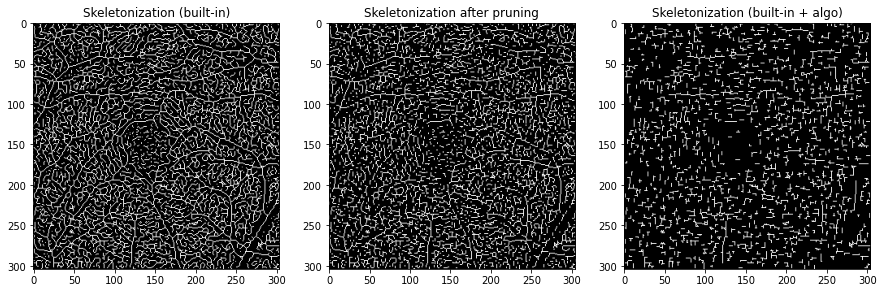

In [12]:
fig, ax = plt.subplots(1, 3, figsize = (15, 15))

ax[0].imshow(test, cmap = 'gray')
ax[0].set_title("Skeletonization (built-in)")

ax[1].imshow(test2, cmap = 'gray')
ax[1].set_title("Skeletonization after pruning")

ax[2].imshow(test3[0], cmap = 'gray')
ax[2].set_title("Skeletonization (built-in + algo)")